In [167]:
#imports
import matplotlib.pyplot as plt
import numpy as np
import pickle

import copy
from pathlib import Path


import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# Set random seeds for reproducibility (same as Exercise 2)
np.random.seed(42)
torch.manual_seed(42)

print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.14.1+cu130


In [168]:
#load the data file
with open("delta_data.pkl", "rb") as file:
    delta_data = pickle.load(file)

In [169]:
def deltas_to_strokes(trajectory):
    """
    Reconstructs (x, y) strokes from (dx, dy, pen_state).
    
    pen_state = 0: pen is DOWN (this step is part of a stroke -> draw it)
    pen_state = 1: pen is UP   (this step is an air move -> skip it)
    """
    strokes = []
    current_stroke = []
    
    x, y = 0.0, 0.0
    
    for dx, dy, pen_state in trajectory:
        prev_x, prev_y = x, y
        x = x + dx
        y = y + dy
        
        if pen_state == 0:
            # Pen is DOWN: include this step in the current stroke
            if not current_stroke:
                # First point of the stroke: include the "from" position too
                current_stroke.append((prev_x, prev_y))
            current_stroke.append((x, y))
            
        else:
            # Pen is UP: flying through the air
            # Save the stroke we were drawing (if any) and reset
            if current_stroke:
                strokes.append(current_stroke)
                current_stroke = []
                
    # Save the last stroke if it exists
    if current_stroke:
        strokes.append(current_stroke)        
    return strokes




Character 'a' has 1 strokes after reconstruction.
Character 'b' has 1 strokes after reconstruction.
Character 'c' has 1 strokes after reconstruction.
Character 'A' has 2 strokes after reconstruction.
Character 'B' has 1 strokes after reconstruction.
Character 'C' has 1 strokes after reconstruction.
Character '1' has 1 strokes after reconstruction.
Character '2' has 1 strokes after reconstruction.
Character '3' has 1 strokes after reconstruction.


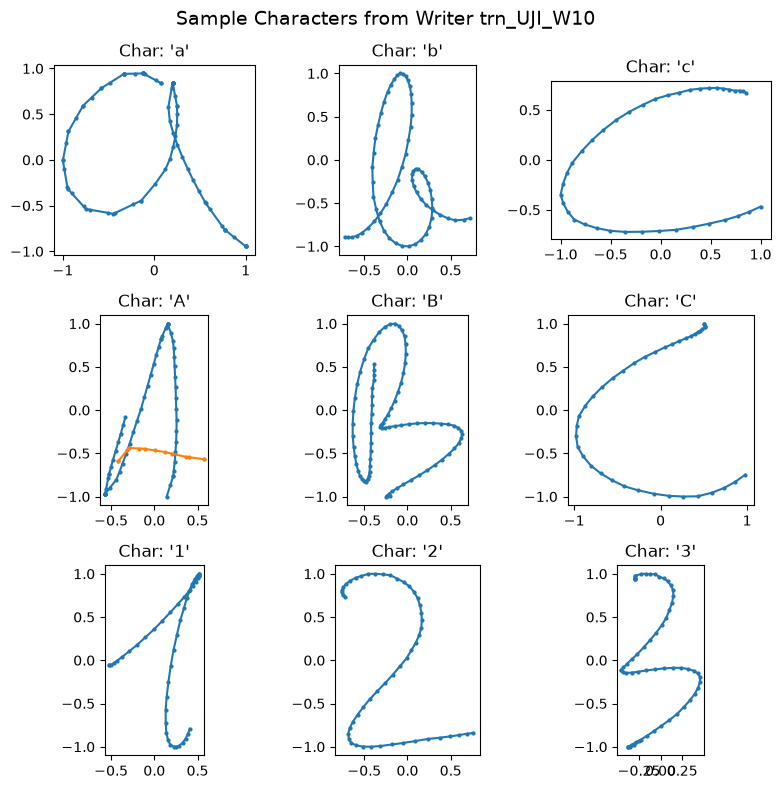

In [170]:
# Plot from delta_data
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']
writer = "trn_UJI_W10"

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    # Get the flat trajectory from delta_data
    trajectory = delta_data[writer][char][0]
    
    # Reconstruct strokes from (dx, dy, pen_state)
    strokes = deltas_to_strokes(trajectory)
    print(f"Character '{char}' has {len(strokes)} strokes after reconstruction.")
    
    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)
        
    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle(f"Sample Characters from Writer {writer}", fontsize=14)
plt.tight_layout()
plt.show()

In [171]:
train_data = {}
val_data = {}
test_data = {}

# 1. Collect all test writer IDs
test_writer_ids = []
for writer_id in delta_data:
    if writer_id.startswith("tst_"):
        test_writer_ids.append(writer_id)

test_writer_ids.sort()

# 2. Split the 20 test writers in half (10 for val, 10 for test)
val_writers = test_writer_ids[:10]
test_writers = test_writer_ids[10:]

# 3. Fill the dictionaries
for writer_id in delta_data:
    if writer_id.startswith("trn_"):
        train_data[writer_id] = delta_data[writer_id]
    elif writer_id in val_writers:
        val_data[writer_id] = delta_data[writer_id]
    elif writer_id in test_writers:
        test_data[writer_id] = delta_data[writer_id]

# 4. Count total samples in each set
def count_samples(dataset):
    total = 0
    for writer_id in dataset:
        for char in dataset[writer_id]:
            total += len(dataset[writer_id][char])
    return total

print(f"Training set:   {len(train_data)} writers | {count_samples(train_data)} samples")
print(f"Validation set: {len(val_data)} writers | {count_samples(val_data)} samples")
print(f"Test set:       {len(test_data)} writers | {count_samples(test_data)} samples")

Training set:   40 writers | 7760 samples
Validation set: 10 writers | 1940 samples
Test set:       10 writers | 1940 samples


Character 'a' has 1 strokes after reconstruction.
Character 'b' has 1 strokes after reconstruction.
Character 'c' has 1 strokes after reconstruction.
Character 'A' has 2 strokes after reconstruction.
Character 'B' has 1 strokes after reconstruction.
Character 'C' has 1 strokes after reconstruction.
Character '1' has 1 strokes after reconstruction.
Character '2' has 1 strokes after reconstruction.
Character '3' has 1 strokes after reconstruction.


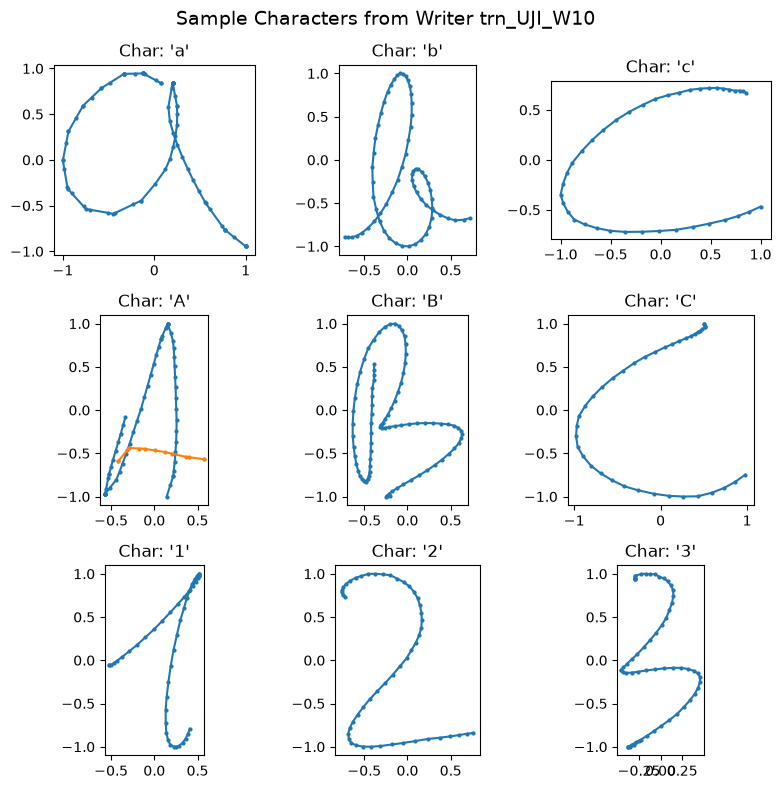

In [172]:
# Plot from delta_data
characters = ['a', 'b', 'c', 'A', 'B', 'C', '1', '2', '3']
writer = "trn_UJI_W10"

fig, axes = plt.subplots(3, 3, figsize=(8, 8))

for ax, char in zip(axes.flat, characters):
    # Get the flat trajectory from delta_data
    trajectory = train_data[writer][char][0]
    
    # Reconstruct strokes from (dx, dy, pen_state)
    strokes = deltas_to_strokes(trajectory)
    print(f"Character '{char}' has {len(strokes)} strokes after reconstruction.")
    
    for stroke in strokes:
        xs = [p[0] for p in stroke]
        ys = [p[1] for p in stroke]
        ax.plot(xs, ys, "-o", markersize=2)
        
    ax.set_aspect("equal")
    ax.set_title(f"Char: '{char}'")

plt.suptitle(f"Sample Characters from Writer {writer}", fontsize=14)
plt.tight_layout()
plt.show()

In [173]:
# 1. Collect all unique characters and give each one a unique number (0, 1, 2, ...)
all_chars = []
for writer_id in delta_data:
    for char in delta_data[writer_id]:
        if char not in all_chars:
            all_chars.append(char)

#char_to_id = {char: i for i , char in enumerate(all_chars)}
char_to_id = {}
for i in range(len(all_chars)):
    char_to_id[all_chars[i]] = i

num_chars = len(all_chars)

print(f"Total unique characters: {num_chars}")

# 2. Build dataset lists with the shared char_to_id
def build_dataset_lists(data_split):
    c_list = []
    X_list = []
    y_list = []

    for writer_id in data_split:
        for char in data_split[writer_id]:
            c_id = char_to_id[char]  # Uses the shared character ID

            for rep in data_split[writer_id][char]:
                traj = np.array(rep, dtype=np.float32)
                len_traj = len(traj)
                inp = traj[0:len_traj-1]  # step 0 to T-2

                inp = np.concatenate([np.array([[0.0, 0.0, 1.0]], dtype=np.float32), inp],axis=0)
                tgt = traj[0:len_traj]   # step 1 to T-1
                c_list.append(c_id)
                X_list.append(inp)
                y_list.append(tgt)

    return c_list, X_list, y_list


c_train, X_train, y_train = build_dataset_lists(train_data)
c_val,   X_val,   y_val   = build_dataset_lists(val_data)
c_test,  X_test,  y_test  = build_dataset_lists(test_data)

Total unique characters: 97


In [174]:
# ==============================================================================
# 1. Calculate Coordinate Mean & Std from Training Trajectories
# ==============================================================================
# Collect all training dx, dy points to compute normalizers
all_train_deltas = np.concatenate([seq[:, :2] for seq in X_train], axis=0)

coord_mean = all_train_deltas.mean(axis=0)
coord_std = all_train_deltas.std(axis=0)
# Avoid division by zero
coord_std = np.clip(coord_std, a_min=1e-6, a_max=None)

print(f"Coordinate Mean (dx, dy): {coord_mean}")
print(f"Coordinate Std  (dx, dy): {coord_std}")

# ==============================================================================
# 2. Find Maximum Sequence Length
# ==============================================================================
max_len = 0
for seq in X_train + X_val + X_test:
  if len(seq) > max_len:
    max_len = len(seq)

print("Maximum sequence length:", max_len)


# ==============================================================================
# 3. Normalized & One-Hot Padding Function
# ==============================================================================
def pad_data(c_list, X_list, y_list, max_len, mean, std):
  total_samples = len(X_list)

  # X_padded: 5 channels -> [norm_dx, norm_dy, is_down, is_up, is_end]
  X_padded = np.zeros((total_samples, max_len, 5), dtype=np.float32)

  # y_padded: 3 channels -> [norm_dx, norm_dy, pen_state_int]
  y_padded = np.zeros((total_samples, max_len, 3), dtype=np.float32)

  mask = np.zeros((total_samples, max_len), dtype=bool)

  for i in range(total_samples):
    seq_len = len(X_list[i])

    # 1. Normalize input coordinates
    norm_dx_dy_in = (X_list[i][:, :2] - mean) / std
    pen_in = X_list[i][:, 2].astype(int)

    # Convert pen state (0, 1, 2) to 3-channel one-hot
    one_hot_pen = np.zeros((seq_len, 3), dtype=np.float32)
    one_hot_pen[np.arange(seq_len), np.clip(pen_in, 0, 2)] = 1.0

    X_padded[i, :seq_len, :2] = norm_dx_dy_in
    X_padded[i, :seq_len, 2:] = one_hot_pen

    # 2. Normalize target coordinates (leave pen_target as integer class 0, 1, 2 for CrossEntropy)
    norm_dx_dy_tgt = (y_list[i][:, :2] - mean) / std
    y_padded[i, :seq_len, :2] = norm_dx_dy_tgt
    y_padded[i, :seq_len, 2] = y_list[i][:, 2]

    # Valid points mask
    mask[i, :seq_len] = True

  c_array = np.array(c_list, dtype=np.int64)
  return c_array, X_padded, y_padded, mask


# ==============================================================================
# 4. Apply Padding & Normalization to Train, Val, and Test
# ==============================================================================
c_train_pad, X_train_pad, y_train_pad, mask_train = pad_data(
    c_train, X_train, y_train, max_len, coord_mean, coord_std
)
c_val_pad, X_val_pad, y_val_pad, mask_val = pad_data(
    c_val, X_val, y_val, max_len, coord_mean, coord_std
)
c_test_pad, X_test_pad, y_test_pad, mask_test = pad_data(
    c_test, X_test, y_test, max_len, coord_mean, coord_std
)

print(
    "Padded X_train shape (samples, time, 5):", X_train_pad.shape
)  # (samples, max_len, 5)
print(
    "Padded y_train shape (samples, time, 3):", y_train_pad.shape
)  # (samples, max_len, 3)
print("Mask train shape:                       ", mask_train.shape)

Coordinate Mean (dx, dy): [ 0.00593893 -0.00270529]
Coordinate Std  (dx, dy): [0.117885  0.1608423]
Maximum sequence length: 97
Padded X_train shape (samples, time, 5): (7760, 97, 5)
Padded y_train shape (samples, time, 3): (7760, 97, 3)
Mask train shape:                        (7760, 97)


In [175]:
# Convert to PyTorch Datasets
train_dataset = TensorDataset(
    torch.tensor(c_train_pad),
    torch.tensor(X_train_pad),
    torch.tensor(y_train_pad),
    torch.tensor(mask_train)
)

val_dataset = TensorDataset(
    torch.tensor(c_val_pad),
    torch.tensor(X_val_pad),
    torch.tensor(y_val_pad),
    torch.tensor(mask_val)
)

test_dataset = TensorDataset(
    torch.tensor(c_test_pad),
    torch.tensor(X_test_pad),
    torch.tensor(y_test_pad),
    torch.tensor(mask_test)
)
train_loader = DataLoader(train_dataset)
val_loader   = DataLoader(val_dataset)
test_loader  = DataLoader(test_dataset)

In [176]:
# ==============================================================================
# CELL 8: MODEL ARCHITECTURE (LSTM WITH PRIMED HIDDEN STATE)
# ==============================================================================


class HandwritingLSTM(nn.Module):

  def __init__(
      self,
      num_chars,
      hidden_size=128,
      num_layers=3,
      embedding_dim=32,
      num_mixtures=5,
  ):
    super().__init__()
    self.hidden_size = hidden_size
    self.num_layers = num_layers
    self.num_mixtures = num_mixtures

    self.char_embedding = nn.Embedding(num_chars, embedding_dim)

    # Project character embedding to initial hidden & cell states
    self.init_h = nn.Linear(embedding_dim, hidden_size * num_layers)
    self.init_c = nn.Linear(embedding_dim, hidden_size * num_layers)

    # 5 inputs: (norm_dx, norm_dy, p_down, p_up, p_end) + embedding_dim
    self.lstm = nn.LSTM(
        input_size=5 + embedding_dim,
        hidden_size=hidden_size,
        num_layers=num_layers,
        batch_first=True,
    )

    # MDN head: pi (K), mu (2*K), log_sigma (2*K)
    self.xy_head = nn.Linear(hidden_size, 5 * num_mixtures)
    self.pen_head = nn.Linear(hidden_size, 3)

  def get_initial_state(self, c):
    batch_size = c.shape[0]
    char_emb = self.char_embedding(c.long())
    h0 = (
        torch.tanh(self.init_h(char_emb))
        .view(batch_size, self.num_layers, self.hidden_size)
        .permute(1, 0, 2)
        .contiguous()
    )
    c0 = (
        torch.tanh(self.init_c(char_emb))
        .view(batch_size, self.num_layers, self.hidden_size)
        .permute(1, 0, 2)
        .contiguous()
    )
    return (h0, c0)

  def forward(self, x, c, hidden=None):
    seq_len = x.shape[1]
    char_emb = self.char_embedding(c.long())

    # Automatically initialize recurrent state if not provided
    if hidden is None:
      hidden = self.get_initial_state(c)

    char_emb_seq = char_emb.unsqueeze(1).expand(-1, seq_len, -1)
    lstm_input = torch.cat([x, char_emb_seq], dim=-1)

    output, hidden = self.lstm(lstm_input, hidden)

    xy_pred = self.xy_head(output)
    pen_logits = self.pen_head(output)

    return xy_pred, pen_logits, hidden

In [179]:
# ==============================================================================
# CELL 9 & 10: LOSS FUNCTION & INITIALIZATION
# ==============================================================================
import math
import torch.nn.functional as F

# Device selection
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Pen-state class balancing using square-root inverse weights
train_pen = train_dataset.tensors[2][:, :, 2].long()
train_mask = train_dataset.tensors[3].bool()

class_counts = torch.bincount(train_pen[train_mask], minlength=3).float()
pen_class_weights = (class_counts.max() / class_counts).to(device)
print("Pen class counts: ", class_counts.cpu().numpy())
print("Pen class weights:", pen_class_weights.cpu().numpy())


def compute_loss_and_metrics(predictions, targets, mask, pen_weight=1.0):
  xy_mdn, pen_logits, _ = predictions

  xy_target = targets[:, :, :2]
  pen_target = targets[:, :, 2].long()

  mask_float = mask.float()
  n_valid = mask_float.sum().clamp(min=1)

  # ----------------------------------------------------
  # Coordinate MDN Loss (Evaluated in Normalized Space)
  # ----------------------------------------------------
  K = xy_mdn.shape[-1] // 5
  pi_logits, mu, log_sigma = torch.split(xy_mdn, [K, 2 * K, 2 * K], dim=-1)

  mu = mu.reshape(*mu.shape[:2], K, 2)
  log_sigma = log_sigma.reshape(*log_sigma.shape[:2], K, 2).clamp(
      min=-3.0, max=2.0
  )

  # Standardized error in normalized coordinates
  xy_error = xy_target.unsqueeze(2) - mu
  standardized_error = xy_error / torch.exp(log_sigma)

  log_gaussian = (
      -0.5 * (standardized_error**2).sum(dim=-1)
      - log_sigma.sum(dim=-1)
      - math.log(2 * math.pi)
  )

  log_pi = F.log_softmax(pi_logits, dim=-1)
  xy_nll = -torch.logsumexp(log_pi + log_gaussian, dim=-1)
  coord_loss = (xy_nll * mask_float).sum() / n_valid

  # ----------------------------------------------------
  # Pen-State Cross-Entropy Loss
  # ----------------------------------------------------
  pen_target = pen_target.masked_fill(~mask, 0)
  pen_ce = F.cross_entropy(
      pen_logits.transpose(1, 2),
      pen_target,
      weight=pen_class_weights,
      reduction="none",
  )
  pen_loss = (pen_ce * mask_float).sum() / n_valid

  loss = coord_loss + pen_weight * pen_loss
  return loss, coord_loss, pen_loss

Using device: cuda
Pen class counts:  [450018.  12352.   7760.]
Pen class weights: [ 1.       36.432804 57.992012]


In [180]:

# ==============================================================================
# 3. TRAINING CONFIGURATION & INITIALIZATION (MDN)
# ==============================================================================

# Model hyperparameters
LSTM_HIDDEN = 128
LSTM_LAYERS = 3
EMBEDDING_DIM = 32

# MDN hyperparameters
NUM_MIXTURES = 5
NUM_PEN_CLASSES = 3

# Training hyperparameters
BATCH_SIZE = 32
PATIENCE = 30
MIN_IMPROVEMENT = 1e-6
PRINT_EVERY = 1

# Pen-state loss weight
PEN_WEIGHT = 1

torch.manual_seed(42)
np.random.seed(42)

# CPU selected because the installed PyTorch CUDA build
# was incompatible with your NVIDIA MX230
device = torch.device("cpu")

print("Using device:", device)

# ----------------------------------------------------
# A. DataLoaders
# ----------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ----------------------------------------------------
# B. Calculate coordinate standard deviations
# ----------------------------------------------------

train_targets = train_dataset.tensors[2]
train_masks = train_dataset.tensors[3].bool()

valid_xy = train_targets[:, :, :2][train_masks]

coord_std = valid_xy.std(
    dim=0, correction=0
).clamp(min=1e-6).to(device)

print("Coordinate standard deviations:", coord_std)

# ----------------------------------------------------
# C. Initialize the LSTM with MDN output
# ----------------------------------------------------

model = HandwritingLSTM(
    num_chars=num_chars,
    hidden_size=LSTM_HIDDEN,
    num_layers=LSTM_LAYERS,
    embedding_dim=EMBEDDING_DIM
).to(device)


print(model)

n_parameters = sum(
    p.numel() for p in model.parameters()
)

print(f"\nLearnable parameters: {n_parameters:,}")

# ----------------------------------------------------
# D. Initialize training history
# ----------------------------------------------------

metrics = [
    "loss",
    "coord_loss",
    "pen_loss",
]

history = {}

for metric in metrics:
    history["train_" + metric] = []
    history["val_" + metric] = []

# ----------------------------------------------------
# E. Initialize early stopping and checkpoints
# ----------------------------------------------------

best_trn_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
best_epoch = -1

stage_boundary_epoch = None


Using device: cpu
Coordinate standard deviations: tensor([1.0003, 1.0002])
HandwritingLSTM(
  (char_embedding): Embedding(97, 32)
  (init_h): Linear(in_features=32, out_features=384, bias=True)
  (init_c): Linear(in_features=32, out_features=384, bias=True)
  (lstm): LSTM(37, 128, num_layers=3, batch_first=True)
  (xy_head): Linear(in_features=128, out_features=25, bias=True)
  (pen_head): Linear(in_features=128, out_features=3, bias=True)
)

Learnable parameters: 381,756


In [ ]:

# ==============================================================================
# 4. TRAINING LOOP
# ==============================================================================

# ==============================================================================
# CELL 11: EPOCH EXECUTION FUNCTION
# ==============================================================================


def run_epoch(loader, optimizer=None):
  training = optimizer is not None
  model.train(training)

  totals = {"loss": 0.0, "coord_loss": 0.0, "pen_loss": 0.0, "pen_acc": 0.0}
  total_valid_points = 0
  total_true_up = 0
  total_correct_up = 0

  with torch.set_grad_enabled(training):
    for batch_c, batch_X, batch_y, batch_mask in loader:
      batch_c = batch_c.to(device)
      batch_X = batch_X.to(device)
      batch_y = batch_y.to(device)
      batch_mask = batch_mask.to(device)

      if training:
        optimizer.zero_grad()
        # Input coordinate jitter to fight exposure bias during autoregression
        jitter = torch.randn_like(batch_X[:, :, :2]) * 0.05
        batch_X_input = batch_X.clone()
        batch_X_input[:, :, :2] += jitter
      else:
        batch_X_input = batch_X

      predictions = model(batch_X_input, batch_c)

      loss, coord_l, pen_l = compute_loss_and_metrics(
          predictions, batch_y, batch_mask, PEN_WEIGHT
      )

      if training:
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

      n = batch_mask.sum().item()
      total_valid_points += n

      totals["loss"] += loss.item() * n
      totals["coord_loss"] += coord_l.item() * n
      totals["pen_loss"] += pen_l.item() * n

      with torch.no_grad():
        pen_logits = predictions[1]
        predicted_pen = torch.argmax(pen_logits, dim=-1)
        actual_pen = batch_y[:, :, 2].long()
        valid_mask = batch_mask.bool()

        correct = (predicted_pen == actual_pen) & valid_mask
        totals["pen_acc"] += correct.sum().item()

        actual_up = (actual_pen == 1) & valid_mask
        predicted_up = (predicted_pen == 1) & valid_mask
        total_true_up += actual_up.sum().item()
        total_correct_up += (predicted_up & actual_up).sum().item()

  results = {k: v / total_valid_points for k, v in totals.items()}
  results["pen_up_recall"] = (
      total_correct_up / total_true_up if total_true_up > 0 else 0.0
  )
  return results

# ==============================================================================
# CELL 12: STAGE 1 TRAINING (LR = 1e-3)
# ==============================================================================

optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
PATIENCE = 15
MIN_IMPROVEMENT = 1e-4
MAX_EPOCHS = 80

best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
best_epoch = -1
epochs_without_improvement = 0

metrics = ["loss", "coord_loss", "pen_loss"]
history = {"train_" + m: [] for m in metrics}
history.update({"val_" + m: [] for m in metrics})

print("Starting Stage 1 Training...")
for epoch in range(MAX_EPOCHS):
  train_results = run_epoch(train_loader, optimizer=optimizer)
  val_results = run_epoch(val_loader, optimizer=None)

  for m in metrics:
    history["train_" + m].append(train_results[m])
    history["val_" + m].append(val_results[m])

  current_epoch = len(history["train_loss"])
  val_loss = val_results["loss"]

  # Checkpoint based on VALIDATION loss
  if val_loss < best_val_loss - MIN_IMPROVEMENT:
    best_val_loss = val_loss
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = current_epoch
    epochs_without_improvement = 0
  else:
    epochs_without_improvement += 1

  print(
      f"Epoch {current_epoch:2d} | "
      f"Train Loss: {train_results['loss']:.4f} | "
      f"Val Loss: {val_results['loss']:.4f} | "
      f"Val Pen Acc: {val_results['pen_acc']:.3f} | "
      f"Val Pen-up Recall: {val_results['pen_up_recall']:.3f}"
  )

  if epochs_without_improvement >= PATIENCE:
    print(f"\nEarly stopping at epoch {current_epoch}")
    break

# Restore best weights
model.load_state_dict(best_state)
torch.save(model.state_dict(), "lstm_mdn_stage1.pth")
print(
    f"Best Stage 1 Epoch: {best_epoch} with Val Loss: {best_val_loss:.5f}\n"
)




In [ ]:
# ==============================================================================
# CELL 14: STAGE 2 FINE-TUNING (LR = 1e-4)
# ==============================================================================

optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
PATIENCE_STAGE2 = 15
MIN_IMPROVEMENT_STAGE2 = 1e-4
MAX_EPOCHS_STAGE2 = 80

best_val_loss_stage2 = float("inf")
best_state_stage2 = copy.deepcopy(model.state_dict())
best_epoch_stage2 = 0
epochs_without_improvement = 0

print("Starting Stage 2 Fine-Tuning...")
try:
  for epoch in range(MAX_EPOCHS_STAGE2):
    train_results = run_epoch(train_loader, optimizer=optimizer)
    val_results = run_epoch(val_loader, optimizer=None)

    for m in metrics:
      history["train_" + m].append(train_results[m])
      history["val_" + m].append(val_results[m])

    current_epoch = len(history["train_loss"])
    val_loss = val_results["loss"]

    if val_loss < best_val_loss_stage2 - MIN_IMPROVEMENT_STAGE2:
      best_val_loss_stage2 = val_loss
      best_state_stage2 = copy.deepcopy(model.state_dict())
      best_epoch_stage2 = current_epoch
      epochs_without_improvement = 0
      torch.save(best_state_stage2, "lstm_mdn_stage2_best.pth")
    else:
      epochs_without_improvement += 1

    print(
        f"Epoch {current_epoch:2d} | "
        f"Train: {train_results['loss']:.4f} | "
        f"Val: {val_results['loss']:.4f} | "
        f"Pen Acc: {val_results['pen_acc']:.3f} | "
        f"Up Recall: {val_results['pen_up_recall']:.3f}"
    )

    if epochs_without_improvement >= PATIENCE_STAGE2:
      print(f"\nEarly stopping at epoch {current_epoch}")
      break

except KeyboardInterrupt:
  print("\nInterrupted. Restoring best Stage 2 weights.")

model.load_state_dict(best_state_stage2)
torch.save(model.state_dict(), "lstm_mdn_stage2_final.pth")
print(f"Best Stage 2 Epoch: {best_epoch_stage2} | Val Loss: {best_val_loss_stage2:.5f}")

In [ ]:
# ==============================================================================
# CELL 15: TEMPERATURE-SCALED TRAJECTORY SAMPLER
# ==============================================================================


def generate_trajectory(
    model,
    char_id,
    max_steps=200,
    temperature=0.35,
    end_threshold=0.5,
    up_threshold=0.4,
):
  model.eval()
  c = torch.tensor([char_id], dtype=torch.long, device=device)

  # Initial step: pen starts in the air, 0 displacement
  # [norm_dx=0, norm_dy=0, is_down=0, is_up=1, is_end=0]
  x_t = torch.tensor(
      [0.0, 0.0, 0.0, 1.0, 0.0], dtype=torch.float32, device=device
  ).view(1, 1, 5)

  hidden = model.get_initial_state(c)
  trajectory = []

  mean_x = coord_mean[0].item()
  mean_y = coord_mean[1].item()
  std_x = coord_std[0].item()
  std_y = coord_std[1].item()

  with torch.no_grad():
    for t in range(max_steps):
      xy_mdn, pen_logits, hidden = model(x_t, c, hidden)

      # ----------------------------------------------------
      # 1. Sample Coordinate Deltas with Temperature
      # ----------------------------------------------------
      mdn = xy_mdn[0, 0]
      K = mdn.shape[-1] // 5
      pi_logits, mu, log_sigma = torch.split(mdn, [K, 2 * K, 2 * K], dim=-1)

      # Sample mixture component
      pi_probs = F.softmax(pi_logits / temperature, dim=-1)
      component = torch.multinomial(pi_probs, 1).item()

      mu_k = mu.reshape(K, 2)[component]
      sigma_k = torch.exp(
          log_sigma.reshape(K, 2)[component].clamp(min=-3.0, max=2.0)
      )

      # Stochastic deviation
      eps = torch.randn(2, device=device)
      norm_delta = mu_k + (sigma_k * temperature) * eps

      # ----------------------------------------------------
      # 2. Pen State Selection
      # ----------------------------------------------------
      pen_probs = F.softmax(pen_logits[0, 0], dim=-1)

      # Stop if end-of-character probability passes threshold
      if t >= 5 and pen_probs[2].item() > end_threshold:
        break

      # Pen up vs. Pen down
      pen = 1 if pen_probs[1].item() > up_threshold else 0

      # ----------------------------------------------------
      # 3. Un-normalize to Original Space
      # ----------------------------------------------------
      real_dx = (norm_delta[0].item() * std_x) + mean_x
      real_dy = (norm_delta[1].item() * std_y) + mean_y
      trajectory.append([real_dx, real_dy, pen])

      # ----------------------------------------------------
      # 4. Feedback Input for Next Step
      # ----------------------------------------------------
      p_down = 1.0 if pen == 0 else 0.0
      p_up = 1.0 if pen == 1 else 0.0

      next_input = torch.tensor(
          [norm_delta[0].item(), norm_delta[1].item(), p_down, p_up, 0.0],
          dtype=torch.float32,
          device=device,
      ).view(1, 1, 5)

      x_t = next_input

  return np.array(trajectory, dtype=np.float32).reshape(-1, 3)

In [ ]:
# ==============================================================================
# CELL 16: GENERATE & PLOT ALL CHARACTERS
# ==============================================================================
import math

ncols = 8
nrows = math.ceil(num_chars / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(2.2 * ncols, 2.2 * nrows))
axes = axes.flatten()

for i, char in enumerate(all_chars):
  ax = axes[i]
  # Sample with low temperature (crisp strokes without mode collapse)
  traj = generate_trajectory(
      model,
      char_to_id[char],
      max_steps=200,
      temperature=0.35,
      end_threshold=0.45,
  )

  strokes = deltas_to_strokes(traj)

  for stroke in strokes:
    xs = [p[0] for p in stroke]
    ys = [p[1] for p in stroke]
    ax.plot(xs, ys, linewidth=1.5)

  ax.set_title(f"'{char}' ({len(traj)})", fontsize=10)
  ax.set_aspect("equal")
  ax.invert_yaxis()  # UJI coordinates have Y increasing downwards
  ax.axis("off")

# Hide any empty subplot axes
for j in range(num_chars, len(axes)):
  axes[j].axis("off")

plt.tight_layout()
plt.show()